# Week 8 Participation Activity: Internet sales forecast

Using the Internet Sales data set to plot a trend line on sales, forecast sales for the next five years, and use summary statistics to find the product most likely to generate the most sales.

## Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MultipleLocator
from scipy import stats

# InternetSales.csv needs to be in the same folder as this notebook. In Colab, upload it with
# the Files pane on the left, or mount Google Drive and use the file's full path.
# The file isn't UTF-8 (accented letters are saved as Latin-1), so read_csv needs
# encoding='latin-1'; low_memory=False stops a mixed-type warning on one column.
sales = pd.read_csv('InternetSales.csv', encoding='latin-1', low_memory=False)
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'], format='%m/%d/%Y')

print(sales.shape)
print('Orders run from', sales['OrderDate'].min().date(), 'to', sales['OrderDate'].max().date())

(60398, 60)
Orders run from 2010-12-29 to 2014-01-28


## Monthly sales

In [2]:
# Total sales for each month
monthly_sales = sales.groupby(sales['OrderDate'].dt.to_period('M'))['SalesAmount'].sum()

# The first and last months are incomplete: December 2010 has only three days of
# orders, and January 2014 stops on the 28th with no bike sales at all (bikes bring
# in most of the revenue). Leave them out so they don't distort the trend.
for month, total in monthly_sales.iloc[[0, -1]].items():
    print(f'Left out {month}: ${total:,.0f}')

monthly_sales = monthly_sales.loc['2011-01':'2013-12']
print(f'\nUsing {len(monthly_sales)} full months: {monthly_sales.index[0]} to {monthly_sales.index[-1]}')

Left out 2010-12: $43,421
Left out 2014-01: $45,695

Using 36 full months: 2011-01 to 2013-12


## Task 4: Trend line on the sales

In [3]:
# Number the months 0, 1, 2, ... so a straight line can be fitted to them
month_number = np.arange(len(monthly_sales))
month_start = monthly_sales.index.to_timestamp()  # the first day of each month, for plotting

# Fit a straight-line trend with least squares: sales = slope * month_number + intercept
slope, intercept = np.polyfit(month_number, monthly_sales.values, 1)
trend = slope * month_number + intercept

# R² is the share of the month-to-month variation in sales that the trend explains
r_squared = np.corrcoef(month_number, monthly_sales.values)[0, 1] ** 2
print(f'Trend: monthly sales grow by about ${slope:,.0f} each month (R² = {r_squared:.2f})')

Trend: monthly sales grow by about $33,393 each month (R² = 0.61)


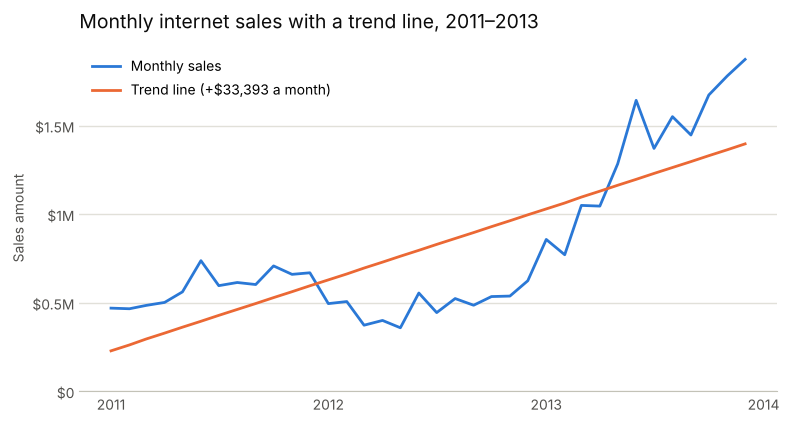

In [4]:
def style_chart(ax, title, tick_step):
    '''Give both charts the same clean look.'''
    ax.set_title(title, loc='left', fontsize=14, color='#0b0b0b', pad=12)
    ax.set_ylabel('Sales amount', color='#52514e')
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_locator(MultipleLocator(tick_step))
    ax.yaxis.set_major_formatter(lambda value, position: f'${value / 1e6:g}M' if value else '$0')
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.grid(axis='y', color='#e1e0d9', linewidth=1)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#c3c2b7')
    ax.tick_params(colors='#52514e', length=0)
    ax.legend(frameon=False, loc='upper left')


fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(month_start, monthly_sales.values, color='#2a78d6', linewidth=2, label='Monthly sales')
ax.plot(month_start, trend, color='#eb6834', linewidth=2, label=f'Trend line (+${slope:,.0f} a month)')
style_chart(ax, 'Monthly internet sales with a trend line, 2011–2013', tick_step=500_000)
plt.show()

## Task 2: Five-year sales forecast

The data ends in January 2014, so the next five years are 2014–2018. The forecast extends the trend line 60 months past December 2013 and adds the monthly values up into yearly totals.

In [5]:
# Extend the trend line 60 months (five years) past the last full month: Jan 2014 to Dec 2018
future_number = np.arange(len(monthly_sales), len(monthly_sales) + 60)
future_start = pd.date_range('2014-01-01', periods=60, freq='MS')
forecast = slope * future_number + intercept

# 95% prediction interval: the range a single future month should fall in if the
# straight-line trend holds. It gets wider the further the forecast is from the data.
n = len(month_number)
std_error = np.sqrt(np.sum((monthly_sales.values - trend) ** 2) / (n - 2))  # typical miss of the trend
t_value = stats.t.ppf(0.975, df=n - 2)
distance = (future_number - month_number.mean()) ** 2 / np.sum((month_number - month_number.mean()) ** 2)
margin = t_value * std_error * np.sqrt(1 + 1 / n + distance)
lower, upper = forecast - margin, forecast + margin

# Add up the monthly forecasts into yearly totals, next to the actual totals for 2011-2013
actual_yearly = monthly_sales.groupby(monthly_sales.index.year).sum()
forecast_yearly = pd.Series(forecast, index=future_start.year).groupby(level=0).sum()
yearly = pd.DataFrame({
    'Type': ['Actual'] * len(actual_yearly) + ['Forecast'] * len(forecast_yearly),
    'Sales': pd.concat([actual_yearly, forecast_yearly]).map('${:,.0f}'.format),
})
yearly.index.name = 'Year'
yearly

,Type,Sales
Year,,
2011,Actual,"$7,075,526"
2012,Actual,"$5,842,485"
2013,Actual,"$16,351,550"
2014,Forecast,"$19,373,754"
2015,Forecast,"$24,182,371"
2016,Forecast,"$28,990,988"
2017,Forecast,"$33,799,604"
2018,Forecast,"$38,608,221"


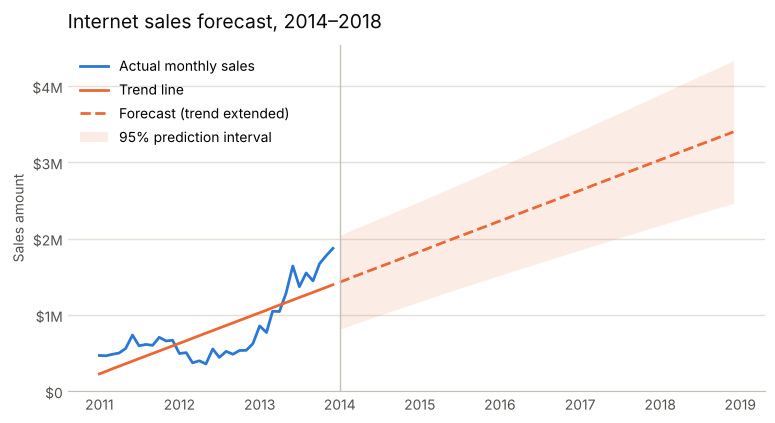

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(month_start, monthly_sales.values, color='#2a78d6', linewidth=2, label='Actual monthly sales')
ax.plot(month_start, trend, color='#eb6834', linewidth=2, label='Trend line')
ax.plot(future_start, forecast, color='#eb6834', linewidth=2, linestyle='--', label='Forecast (trend extended)')
ax.fill_between(future_start, lower, upper, color='#eb6834', alpha=0.12, linewidth=0,
                label='95% prediction interval')
ax.axvline(future_start[0], color='#c3c2b7', linewidth=1)  # where the forecast starts
style_chart(ax, 'Internet sales forecast, 2014–2018', tick_step=1_000_000)
plt.show()

**Forecast:** if the 2011–2013 trend continues, internet sales would rise from about $19.4M in 2014 to about $38.6M in 2018, roughly $4.8M more each year. The shaded band shows how far individual months could plausibly land from the trend line.

This is a rough projection, not a firm prediction. It rests on only three years of history, and 2013 looks very different from 2011–2012, so the straight line fits the data only moderately well (R² = 0.61). Because the line is fitted to all three years, including the weaker 2012, it starts below where sales ended in late 2013. A straight line also ignores seasonal patterns and can't anticipate changes such as new or discontinued products.

## Task 3: Which product will generate the most sales?

In [7]:
# Summary statistics of SalesAmount for each product, sorted by total sales
product_stats = (
    sales.groupby('EnglishProductName')['SalesAmount']
    .agg(order_lines='count', total_sales='sum', average_sale='mean', median_sale='median')
    .sort_values('total_sales', ascending=False)
)
product_stats.head(10).round(2)

,order_lines,total_sales,average_sale,median_sale
EnglishProductName,,,,
"Mountain-200 Black, 46",620,1373469.55,2215.27,2294.99
"Mountain-200 Black, 42",614,1363142.09,2220.10,2294.99
"Mountain-200 Silver, 38",596,1339462.79,2247.42,2319.99
"Mountain-200 Silver, 46",580,1301100.10,2243.28,2319.99
"Mountain-200 Black, 38",582,1294866.14,2224.86,2294.99
"Mountain-200 Silver, 42",560,1257434.57,2245.42,2319.99
"Road-150 Red, 48",337,1205876.99,3578.27,3578.27
"Road-150 Red, 62",336,1202298.72,3578.27,3578.27
"Road-150 Red, 52",302,1080637.54,3578.27,3578.27


In [8]:
# The product mix changes over time, so check the most recent full year too.
# For example, the Road-150 bikes in the all-time top 10 stopped selling after 2011:
road_150 = sales[sales['EnglishProductName'].str.startswith('Road-150')]
print('Last Road-150 sale:', road_150['OrderDate'].max().date())

sales_2013 = sales[sales['OrderDate'].dt.year == 2013]
product_stats_2013 = (
    sales_2013.groupby('EnglishProductName')['SalesAmount']
    .agg(order_lines='count', total_sales='sum', average_sale='mean')
    .sort_values('total_sales', ascending=False)
)
product_stats_2013.head(5).round(2)

Last Road-150 sale: 2011-12-28


,order_lines,total_sales,average_sale
EnglishProductName,,,
"Mountain-200 Black, 42",423,970780.77,2294.99
"Mountain-200 Silver, 38",417,967435.83,2319.99
"Mountain-200 Black, 46",413,947830.87,2294.99
"Mountain-200 Black, 38",413,947830.87,2294.99
"Mountain-200 Silver, 46",398,923356.02,2319.99


In [9]:
# Group the frame sizes together (e.g. 'Mountain-200 Black, 42' -> 'Mountain-200 Black')
# to see which bike model sold the most in 2013
model_2013 = sales_2013['EnglishProductName'].str.replace(r', \d+$', '', regex=True).rename('Model')
model_sales_2013 = sales_2013.groupby(model_2013)['SalesAmount'].sum().sort_values(ascending=False)
model_sales_2013.head(5).map('${:,.0f}'.format)

Model
Mountain-200 Black     $2,866,443
Mountain-200 Silver    $2,793,268
Road-350-W Yellow      $1,571,715
Touring-1000 Blue      $1,501,964
Touring-1000 Yellow    $1,475,739
Name: SalesAmount, dtype: str

**Answer:** over the whole data set, **Mountain-200 Black, 46** has the highest total sales ($1,373,470 from 620 order lines). In 2013, the most recent full year, **Mountain-200 Black, 42** sold slightly more ($970,781), and in both cases the top two products are less than 1% apart. Either way, the product most likely to generate the most sales is the **Mountain-200 Black** mountain bike: it was the top-selling model in 2013, with $2.87M across all frame sizes. The Road-150 Red bikes also rank in the all-time top 10, but they stopped selling after 2011, so they won't generate future sales.